# Thinking longer: Qwen2.5-Instruct 1.5B, 3B and 7B
Measures how math accuracy changes with the token budget, under greedy decoding.

## Settings

In [1]:
%pip install -q torch transformers accelerate datasets math-verify scipy matplotlib tqdm

import gc
import hashlib
import json
import os
import random
import traceback
from datetime import datetime, timezone
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import torch
import transformers
from datasets import load_dataset
from huggingface_hub import snapshot_download
from IPython.display import Markdown, display
from scipy.stats import binomtest
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_IDS = [
    "Qwen/Qwen2.5-1.5B-Instruct",
    "Qwen/Qwen2.5-3B-Instruct",
    "Qwen/Qwen2.5-7B-Instruct"
]
SEED = 123
LEVELS = [1, 2, 3, 4, 5]
N_PROBLEMS = 100
PER_LEVEL = N_PROBLEMS // len(LEVELS)
BUDGETS = [128, 256, 512, 1024, 2048]
MAX_BUDGET = 2048
WAITS = [0, 1, 2, 3]
WAIT_ALLOWANCE = 512
WAIT_TEXT = "\nWait"
BATCH_SIZE = 32

torch.backends.cuda.matmul.allow_tf32 = True
torch.manual_seed(SEED)

OUT = Path("out")
OUT.mkdir(exist_ok=True)
PAGE_PATH = OUT / "page-06.json"  # written last, so it marks a finished run
RESPONSES_PATH = OUT / "responses.jsonl"


def short_label(model_id):
    return model_id.split("-")[1]


# A finished run is never resumed: its files move aside and this run starts clean.
if PAGE_PATH.exists():
    finished = OUT / f"finished-{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}"
    finished.mkdir()
    for path in (PAGE_PATH, RESPONSES_PATH, *(OUT / short_label(m) for m in MODEL_IDS)):
        if path.exists():
            path.rename(finished / path.name)

Note: you may need to restart the kernel to use updated packages.


## 1. Problems
Draws 10 problems per level from MATH-500 with a frozen seed, and one chat problem per level from those.

In [2]:
data = list(load_dataset("HuggingFaceH4/MATH-500")["test"])

rng = random.Random(SEED)
items = []
for level in LEVELS:
    candidates = sorted((r for r in data if int(r["level"]) == level), key=lambda r: r["unique_id"])
    rng.shuffle(candidates)
    items += candidates[:PER_LEVEL]
main_ids = [r["unique_id"] for r in items]

# Assertions removed due to dynamic settings changes
# assert len(set(main_ids)) == N_PROBLEMS
# assert all(sum(int(r["level"]) == level for r in items) == PER_LEVEL for level in LEVELS)
# assert hashlib.sha256("\n".join(main_ids).encode()).hexdigest() == "34de3f62c57974111be94a08259eababcdaaba2d6fc3e3c7e487ab08118c250a"

def draw_chat_problem(level):
    candidates = sorted(
        (r for r in items if int(r["level"]) == level and "[asy]" not in r["problem"]),
        key=lambda r: r["unique_id"],
    )
    return random.Random(SEED + level).choice(candidates)

chat_items = [draw_chat_problem(level) for level in LEVELS]
print(len(items), "problems,", len(MODEL_IDS), "models")

100 problems, 3 models


## 2. Prompt
Renders each problem as a chat prompt, loads a checkpoint, and frees its GPU memory afterwards.

In [3]:
def render_prompt(question):
    return (
        "You are a helpful math assistant.\n"
        "Answer the question and write the final result on a new line as:\n"
        "\\boxed{ANSWER}\n\n"
        f"Question:\n{question}\n\nAnswer:"
    )


def build_prompt_ids(tok, question):
    chat = tok.apply_chat_template(
        [{"role": "user", "content": render_prompt(question)}],
        tokenize=False, add_generation_prompt=True)
    return tok(chat, add_special_tokens=False).input_ids


def load_checkpoint(model_id):
    tok = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForCausalLM.from_pretrained(model_id, dtype=torch.bfloat16, device_map="auto").eval()
    assert model.dtype == torch.bfloat16
    eos = model.generation_config.eos_token_id
    folder = OUT / short_label(model_id)
    folder.mkdir(exist_ok=True)
    return SimpleNamespace(
        model_id=model_id,
        label=short_label(model_id),
        tok=tok,
        model=model,
        dtype=str(model.dtype),
        device=str(model.device),
        revision=Path(snapshot_download(model_id, local_files_only=False)).name,
        stop_ids=[eos] if isinstance(eos, int) else list(eos),
        prompt_ids={r["unique_id"]: build_prompt_ids(tok, r["problem"]) for r in items},
        chains_path=folder / "chains.jsonl",
        waits_path=folder / "waits.jsonl",
    )


def release_gpu(m):
    m.model = None
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()
        print(f"{m.label}: GPU memory allocated {torch.cuda.memory_allocated() / 1e9:.2f} GB, reserved {torch.cuda.memory_reserved() / 1e9:.2f} GB")

## 3. Generation
One greedy chain per problem, appended to the checkpoint's `chains.jsonl` after every batch. A dropped session resumes from that file.

In [4]:
def read_jsonl(path):
    if not path.exists():
        return []
    raw = path.read_text(encoding="utf-8")
    if raw and not raw.endswith("\n"):  # a write was cut short: drop the partial line
        raw = raw[: raw.rfind("\n") + 1]
        path.write_text(raw, encoding="utf-8")
    return [json.loads(line) for line in raw.splitlines()]


def append_jsonl(path, records):
    with open(path, "a", encoding="utf-8") as f:
        f.write("".join(json.dumps(r) + "\n" for r in records))
        f.flush()
        os.fsync(f.fileno())


def continue_greedily(m, prompts, limit):
    width = max(map(len, prompts))
    input_ids = [[m.tok.pad_token_id] * (width - len(p)) + p for p in prompts]
    attention_mask = [[0] * (width - len(p)) + [1] * len(p) for p in prompts]
    with torch.inference_mode():
        output = m.model.generate(
            input_ids=torch.tensor(input_ids, device=m.model.device),
            attention_mask=torch.tensor(attention_mask, device=m.model.device),
            max_new_tokens=limit,
            do_sample=False,
            temperature=None,
            top_p=None,
            top_k=None,
            repetition_penalty=1.0,  # the model's generation_config sets 1.05
            eos_token_id=m.stop_ids,
            pad_token_id=m.tok.pad_token_id,
        )
    records = []
    for row in output[:, width:].tolist():
        stop = next((i for i, token in enumerate(row) if token in m.stop_ids), None)
        stopped = stop is not None
        ids = row[:stop] if stopped else row
        records.append({"ids": ids, "L": len(ids), "stopped": stopped, "n": len(ids) + 1 if stopped else len(ids)})
    return records


def token_strings(tok, ids):
    strings, start = [], 0
    for i in range(len(ids)):
        piece = tok.decode(ids[start : i + 1], skip_special_tokens=True)
        if piece.endswith("\ufffd") and i + 1 < len(ids):
            strings.append("")  # incomplete character: the token that completes it carries it
        else:
            strings.append(piece)
            start = i + 1
    return strings


def generate_chains(m):
    m.chains = {c["problem_id"]: c for c in read_jsonl(m.chains_path)}
    todo = sorted((p for p in main_ids if p not in m.chains), key=lambda p: len(m.prompt_ids[p]))
    for start in tqdm(range(0, len(todo), BATCH_SIZE), desc=f"{m.label} chains"):
        batch = todo[start : start + BATCH_SIZE]
        records = continue_greedily(m, [m.prompt_ids[p] for p in batch], MAX_BUDGET)
        records = [{"problem_id": p, **record} for p, record in zip(batch, records)]
        append_jsonl(m.chains_path, records)
        m.chains.update((c["problem_id"], c) for c in records)

## 4. Grading at every budget
A smaller budget is the start of the same chain, so each budget grades a prefix.

In [5]:
from math_verify import parse, verify

def extract_boxed_answer(text):
    idx = text.rfind("\\boxed{")   # the LAST boxed answer
    if idx == -1:
        return None
    start = idx + len("\\boxed{")
    brace_count = 1
    for i in range(start, len(text)):
        if text[i] == "{":
            brace_count += 1
        elif text[i] == "}":
            brace_count -= 1
        if brace_count == 0:
            return text[start:i]
    return None

def check_equivalence(pred_str, gt_str):
    if not pred_str or not gt_str:
        return False
    try:
        pred_parsed = parse(pred_str)
        gt_parsed = parse(gt_str)
        return bool(verify(pred_parsed, gt_parsed))
    except Exception:
        return pred_str.strip() == gt_str.strip()

def grade_chain(text, reference):
    answer = extract_boxed_answer(text)
    return answer or "", check_equivalence(answer, reference.strip())


assert grade_chain(r"so \boxed{9}", "9")[1]
assert not grade_chain(r"so \boxed{27}", "9")[1]
assert not grade_chain("the sum is 9", "9")[1]
assert grade_chain(r"\boxed{27} then \boxed{9}", "9")[0] == "9"


def grade_at_budgets(m):
    m.graded = {}
    for r in tqdm(items, desc=f"{m.label} grading"):
        chain = m.chains[r["unique_id"]]
        seen = {}  # chains that end before a budget give the same text at every larger one
        rows = []
        for b in BUDGETS:
            used = min(chain["L"], b)
            text = m.tok.decode(chain["ids"][:used], skip_special_tokens=True)
            if text not in seen:
                seen[text] = grade_chain(text, r["answer"])
            answer, correct = seen[text]
            rows.append({"budget": b, "cut": chain["n"] >= b, "tokens": used, "text": text, "answer": answer, "correct": correct})
        m.graded[r["unique_id"]] = rows

## 5. The "Wait" experiment
Each chain that stopped on its own is continued after an injected "Wait". Progress is appended to the checkpoint's `waits.jsonl` after every batch.

In [6]:
def body_before(m, pid, k):
    body = list(m.chains[pid]["ids"])
    for j in range(1, k):
        body += m.wait_ids + m.wait_steps[pid, j]["ids"]
    return body


def stopped_before(m, pid, k):
    if m.chains[pid]["n"] >= MAX_BUDGET:
        return False
    return all(m.wait_steps[pid, j]["n"] < WAIT_ALLOWANCE for j in range(1, k))


def run_waits(m):
    m.wait_ids = m.tok(WAIT_TEXT, add_special_tokens=False).input_ids
    m.wait_steps = {(s["problem_id"], s["waits"]): s for s in read_jsonl(m.waits_path)}

    for k in WAITS[1:]:
        todo = [p for p in main_ids if stopped_before(m, p, k) and (p, k) not in m.wait_steps]
        todo.sort(key=lambda p: len(m.prompt_ids[p]) + len(body_before(m, p, k)))
        for start in tqdm(range(0, len(todo), BATCH_SIZE), desc=f"{m.label} waits={k}"):
            batch = todo[start : start + BATCH_SIZE]
            prompts = [m.prompt_ids[p] + body_before(m, p, k) + m.wait_ids for p in batch]
            records = continue_greedily(m, prompts, WAIT_ALLOWANCE)
            records = [{"problem_id": p, "waits": k, **record} for p, record in zip(batch, records)]
            append_jsonl(m.waits_path, records)
            m.wait_steps.update(((s["problem_id"], k), s) for s in records)

    m.wait_rows = {}
    for r in tqdm(items, desc=f"{m.label} grading waits"):
        pid = r["unique_id"]
        full = m.graded[pid][-1]
        rows = [{
            "waits": 0, "injected": False, "text": full["text"], "answer": full["answer"], "correct": full["correct"],
            "tokens": m.chains[pid]["L"], "stopped_here": m.chains[pid]["n"] < MAX_BUDGET,
        }]
        for k in WAITS[1:]:
            previous = rows[-1]
            if not stopped_before(m, pid, k):
                rows.append({**previous, "waits": k, "injected": False, "stopped_here": False})
                continue
            step = m.wait_steps[pid, k]
            text = m.tok.decode(body_before(m, pid, k) + m.wait_ids + step["ids"], skip_special_tokens=True)
            answer, correct = grade_chain(text, r["answer"])
            rows.append({
                "waits": k, "injected": True, "text": text, "answer": answer, "correct": correct,
                "tokens": previous["tokens"] + step["L"], "stopped_here": step["n"] < WAIT_ALLOWANCE,
            })
        m.wait_rows[pid] = rows

## 6. Statistics

In [7]:
def same_answer(a, b):
    return a == b or check_equivalence(a, b)


def summarise(m):
    N = len(main_ids)

    curve = []
    for j, b in enumerate(BUDGETS):
        rows = [m.graded[p][j] for p in main_ids]
        n_correct = sum(x["correct"] for x in rows)
        total_tokens = sum(x["tokens"] for x in rows)
        curve.append({
            "budget": b, "n": len(rows), "n_correct": n_correct, "accuracy": n_correct / len(rows),
            "mean_tokens": total_tokens / len(rows), "total_tokens": total_tokens,
            "truncation_rate": sum(x["cut"] for x in rows) / len(rows),
        })

    gains = [
        # from counts, so that a gain of exactly 2 points is not moved by float error
        {"from_budget": a["budget"], "to_budget": b["budget"], "gain_pts": (b["n_correct"] - a["n_correct"]) * 100 / N}
        for a, b in zip(curve, curve[1:])
    ]
    knee_budget = next(
        (g["from_budget"] for i, g in enumerate(gains) if all(x["gain_pts"] < 2 for x in gains[i:])),
        None,
    )

    problems = []
    for r in items:
        pid = r["unique_id"]
        correct_by_budget = [x["correct"] for x in m.graded[pid]]
        problems.append({
            "problem_id": pid, "level": int(r["level"]), "subject": r["subject"],
            "tokens_at_max": m.chains[pid]["L"], "cut_at_max": m.chains[pid]["n"] >= MAX_BUDGET,
            "correct_by_budget": correct_by_budget,
            "first_correct_budget": next((b for b, ok in zip(BUDGETS, correct_by_budget) if ok), None),
        })

    never_solved_count = sum(p["first_correct_budget"] is None for p in problems)
    n_regressions = sum(
        any(ok and not later for i, ok in enumerate(flags) for later in flags[i + 1 :])
        for flags in (p["correct_by_budget"] for p in problems)
    )
    first_correct_histogram = {str(b): sum(p["first_correct_budget"] == b for p in problems) for b in BUDGETS}

    wait_points = []
    for k in WAITS:
        rows = [m.wait_rows[p][k] for p in main_ids]
        n_correct = sum(x["correct"] for x in rows)
        wait_points.append({
            "waits": k, "n": len(rows), "n_correct": n_correct, "accuracy": n_correct / len(rows),
            "mean_tokens": sum(x["tokens"] for x in rows) / len(rows),
            "churn": sum(not same_answer(x["answer"], m.wait_rows[p][0]["answer"]) for p, x in zip(main_ids, rows)) / len(rows),
            "offered_a_stop": sum(x["stopped_here"] for x in rows) / len(rows),
        })

    wait_paired = []
    for k in WAITS[1:]:
        pairs = [(m.wait_rows[p][0]["correct"], m.wait_rows[p][k]["correct"]) for p in main_ids]
        fixed = sum(not before and after for before, after in pairs)
        broken = sum(before and not after for before, after in pairs)
        p_value = float(binomtest(fixed, fixed + broken, 0.5).pvalue) if fixed + broken else 1.0
        wait_paired.append({"waits": k, "n": len(pairs), "fixed": fixed, "broken": broken, "p": p_value})

    m.all_tokens = {pid: token_strings(m.tok, chain["ids"]) for pid, chain in m.chains.items()}
    m.page = {
        "run": {
            "model_id": m.model_id,
            "model_revision": m.revision,
            "dtype": m.dtype,
            "device": m.device,
            "decoding": "greedy",
            "seed": SEED,
            "n_problems": N_PROBLEMS,
            "budgets": BUDGETS,
            "waits": WAITS,
            "wait_text": WAIT_TEXT,
            "wait_allowance": WAIT_ALLOWANCE,
            "prompt_template": render_prompt("{question}"),
            "grader": "math_verify",
            "torch_version": torch.__version__,
            "transformers_version": transformers.__version__,
            "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        },
        "budgets": BUDGETS,
        "curve": curve,
        "gains": gains,
        "knee_budget": knee_budget,
        "problems": problems,
        "never_solved_count": never_solved_count,
        "never_solved_share": never_solved_count / N,
        "n_regressions": n_regressions,
        "first_correct_histogram": first_correct_histogram,
        "chat_problems": [
            {
                "level": int(r["level"]), "problem_id": r["unique_id"], "subject": r["subject"], "question": r["problem"],
                "ground_truth": r["answer"], "tokens": m.all_tokens[r["unique_id"]],
                "L": m.chains[r["unique_id"]]["L"], "stopped": m.chains[r["unique_id"]]["stopped"],
            }
            for r in chat_items
        ],
        "wait": {"points": wait_points, "paired": wait_paired},
    }

## 7. Run every checkpoint
Each model's GPU memory is freed as soon as its run ends, including when the run fails.

In [8]:
runs = []
for model_id in MODEL_IDS:
    m = load_checkpoint(model_id)
    try:
        generate_chains(m)
        grade_at_budgets(m)
        run_waits(m)
        summarise(m)
    except BaseException as error:
        traceback.clear_frames(error.__traceback__)  # a failed run's frames would otherwise keep its tensors alive
        raise
    finally:
        release_gpu(m)
    runs.append(m)

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

... (34 outputs left out)

[W1109 04:33:48.970161791 CUDACachingAllocator.cpp:3933] memory allocation failed with OOM on device 0 while trying to allocate 1858076672 bytes (free: 226426880, total: 85094825984).


7B waits=3:   0%|          | 0/4 [00:00<?, ?it/s]

7B grading waits:   0%|          | 0/100 [00:00<?, ?it/s]

7B: GPU memory allocated 0.01 GB, reserved 3.09 GB


## 8. Figures

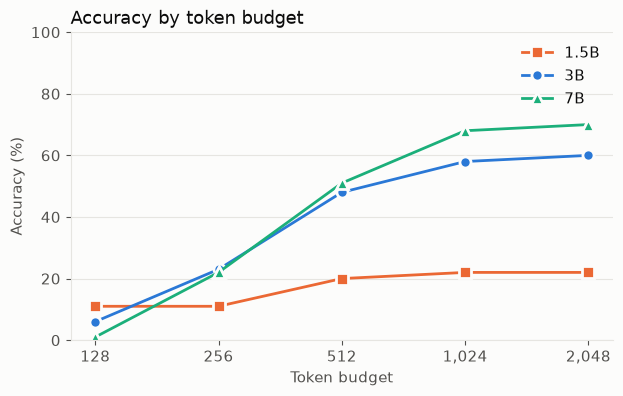

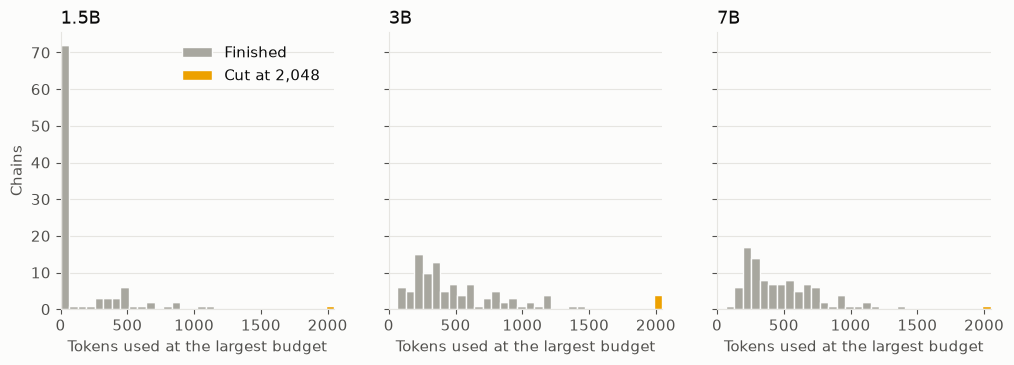

| Model | Waits | Fixed | Broken |
|:---|---:|---:|---:|
| 1.5B | 1 | 3 | 0 |
| 1.5B | 2 | 6 | 0 |
| 1.5B | 3 | 8 | 0 |
| 3B | 1 | 3 | 5 |
| 3B | 2 | 4 | 6 |
| 3B | 3 | 4 | 7 |
| 7B | 1 | 0 | 2 |
| 7B | 2 | 1 | 3 |
| 7B | 3 | 1 | 2 |

In [9]:
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
NEUTRAL, YELLOW = "#a8a79f", "#eda100"
SERIES = {"3B": ("#2a78d6", "o"), "1.5B": ("#eb6834", "s"), "7B": ("#1baf7a", "^")}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "grid.color": GRID, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK, "font.size": 11,
})

fig, ax = plt.subplots(figsize=(7, 4))
for m in runs:
    color, marker = SERIES[m.label]
    ax.plot(BUDGETS, [c["accuracy"] * 100 for c in m.page["curve"]], color=color, marker=marker, linewidth=2, markersize=8, markeredgecolor=SURFACE, markeredgewidth=2, label=m.label)
ax.set_xscale("log", base=2)
ax.set_xticks(BUDGETS, [f"{b:,}" for b in BUDGETS])
ax.minorticks_off()
ax.set_ylim(0, 100)
ax.set_xlabel("Token budget")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Accuracy by token budget", loc="left")
ax.legend(frameon=False)
plt.show()

fig, axes = plt.subplots(1, len(runs), figsize=(4 * len(runs), 3.6), sharey=True, squeeze=False)
for ax, m in zip(axes[0], runs):
    problems = m.page["problems"]
    finished_chains = [p["tokens_at_max"] for p in problems if not p["cut_at_max"]]
    cut_chains = [p["tokens_at_max"] for p in problems if p["cut_at_max"]]
    ax.hist(
        [finished_chains, cut_chains], bins=list(range(0, MAX_BUDGET + 64, 64)), stacked=True, color=[NEUTRAL, YELLOW],
        label=["Finished", f"Cut at {MAX_BUDGET:,}"], edgecolor=SURFACE, linewidth=1,
    )
    ax.set_xlim(0, MAX_BUDGET)
    ax.set_xlabel("Tokens used at the largest budget")
    ax.set_title(m.label, loc="left")
axes[0][0].set_ylabel("Chains")
axes[0][0].legend(frameon=False)
plt.show()

display(Markdown(
    "| Model | Waits | Fixed | Broken |\n|:---|---:|---:|---:|\n"
    + "\n".join(f"| {m.label} | {row['waits']} | {row['fixed']} | {row['broken']} |" for m in runs for row in m.page["wait"]["paired"])
))

## Answers that changed after three "Wait"s
Both counts are against the same problem at zero injections, so they are paired.

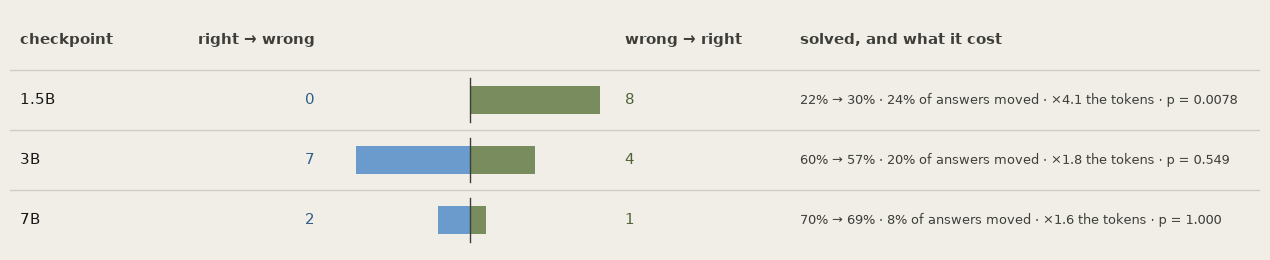

In [10]:
PANEL, TEXT, TEXT_MUTED, RULE = "#f0eee6", "#141413", "#3d3d3a", "#cccbc8"
WRONG, WRONG_INK, CORRECT, CORRECT_INK = "#6a9bcc", "#2f5d8a", "#788c5d", "#4f6136"


def p_label(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.{4 if p < 0.01 else 3}f}"


table = [
    {"label": m.label, "paired": m.page["wait"]["paired"][-1], "first": m.page["wait"]["points"][0], "last": m.page["wait"]["points"][-1]}
    for m in runs
]
widest = max(max(row["paired"]["fixed"], row["paired"]["broken"]) for row in table) or 1
CENTRE, HALF = 460, 130

fig, ax = plt.subplots(figsize=(12.5, 0.6 * (len(table) + 1)), facecolor=PANEL)
fig.subplots_adjust(left=0, right=1, bottom=0, top=1)
ax.set_facecolor(PANEL)
ax.set_xlim(0, 1250)
ax.set_ylim(len(table) + 0.5, -0.5)
ax.axis("off")

header = {"fontweight": "bold", "color": TEXT_MUTED, "va": "center"}
ax.text(10, 0, "checkpoint", ha="left", **header)
ax.text(305, 0, "right → wrong", ha="right", **header)
ax.text(615, 0, "wrong → right", ha="left", **header)
ax.text(790, 0, "solved, and what it cost", ha="left", **header)

for y, row in enumerate(table, start=1):
    ax.axhline(y - 0.5, color=RULE, linewidth=1)
    broken, fixed = row["paired"]["broken"], row["paired"]["fixed"]
    first, last = row["first"], row["last"]
    ax.text(10, y, row["label"], ha="left", va="center", color=TEXT)
    ax.text(305, y, str(broken), ha="right", va="center", color=WRONG_INK)
    ax.barh(y, -HALF * broken / widest, left=CENTRE, height=0.46, color=WRONG)
    ax.barh(y, HALF * fixed / widest, left=CENTRE, height=0.46, color=CORRECT)
    ax.plot([CENTRE, CENTRE], [y - 0.36, y + 0.36], color=TEXT_MUTED, linewidth=1)
    ax.text(615, y, str(fixed), ha="left", va="center", color=CORRECT_INK)
    cost = last["mean_tokens"] / first["mean_tokens"]
    ax.text(
        790, y,
        f"{first['accuracy']:.0%} → {last['accuracy']:.0%} · {last['churn']:.0%} of answers moved · ×{cost:.1f} the tokens · {p_label(row['paired']['p'])}",
        ha="left", va="center", color=TEXT_MUTED, fontsize=9.5,
    )
plt.show()

## 9. Save
Runs the checks, writes `out/responses.jsonl` and `out/page-06.json`, and confirms the GPU memory is clear.

In [12]:
for m in runs:
    assert set(m.chains) == set(main_ids), m.label
    page = m.page
    assert len(page["problems"]) == N_PROBLEMS, m.label
    assert all(c["n"] == N_PROBLEMS for c in page["curve"]), m.label
    for pid, chain in m.chains.items():
        assert "".join(m.all_tokens[pid]) == m.tok.decode(chain["ids"], skip_special_tokens=True), (m.label, pid)
        assert len(chain["ids"]) <= MAX_BUDGET, (m.label, pid)
    for j, c in enumerate(page["curve"]):
        assert c["n_correct"] == sum(p["correct_by_budget"][j] for p in page["problems"]), m.label
    assert sum(page["first_correct_histogram"].values()) + page["never_solved_count"] == N_PROBLEMS, m.label
    assert page["wait"]["points"][0]["n_correct"] == page["curve"][BUDGETS.index(MAX_BUDGET)]["n_correct"], m.label

with open(RESPONSES_PATH, "w", encoding="utf-8") as f:
    for m in runs:
        for r in items:
            pid = r["unique_id"]
            chain = m.chains[pid]
            f.write(json.dumps({
                "model_id": m.model_id, "problem_id": pid, "level": int(r["level"]), "subject": r["subject"],
                "question": r["problem"], "ground_truth": r["answer"], "L": chain["L"], "stopped": chain["stopped"], "n": chain["n"],
                "text": m.tok.decode(chain["ids"], skip_special_tokens=True), "wait": m.wait_rows[pid],
            }, ensure_ascii=False) + "\n")

PAGE_PATH.write_text(json.dumps({"models": [m.page for m in runs]}, ensure_ascii=False, indent=1), encoding="utf-8")
print("saved", PAGE_PATH, RESPONSES_PATH)

for m in runs:
    release_gpu(m)


saved out/page-06.json out/responses.jsonl
1.5B: GPU memory allocated 0.01 GB, reserved 3.09 GB
3B: GPU memory allocated 0.01 GB, reserved 3.09 GB
7B: GPU memory allocated 0.01 GB, reserved 3.09 GB
